# Exploratory Data Analysis (EDA)

## Анализ данных термогравиметрии гидрогелей

В данной работе проводится разведочный анализ данных термогравиметрического анализа (ТГА) гидрогелей на основе карбоксиметил-агара и желатина при различных значениях pH.

Цель работы — изучить структуру и качество датасета, проверить наличие пропущенных значений, дубликатов и аномалий, а также рассчитать основные статистические характеристики.

## 1. Загрузка данных

Для анализа используется датасет термогравиметрического анализа гидрогелей, сохранённый в формате Parquet.

Файл `data.parquet` не хранится в репозитории. Для повторного выполнения анализа его необходимо предварительно создать с помощью скрипта `data_loader.py`.

Сначала загрузим данные и посмотрим на первые строки таблицы.

In [1]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("..") / "data.parquet"

if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Файл data.parquet не найден. Сначала запустите data_loader.py"
    )

df = pd.read_parquet(DATA_PATH)

df.head(10)

,temperature_C,time_min,mass_percent,gas_flow_purge2_mlmin,gas_flow_protective_mlmin,dtg_pct_per_min,sample_id,identity_raw,ph,agar_pct,gelatin_pct,measurement_number,sample_mass_mg,heating_rate_K_min,instrument,crucible_type,experiment_datetime,source_file
0,28.255,0.00000,100.00000,50.0,70.0,-0.318620,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...
1,29.255,0.32236,99.97415,50.0,70.0,-0.077649,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...
2,30.255,0.64002,99.91764,50.0,70.0,-0.134300,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...
3,31.255,0.82179,99.90891,50.0,70.0,0.001488,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...
4,32.255,0.95176,99.92031,50.0,70.0,-0.043305,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...
5,33.255,1.05976,99.90988,50.0,70.0,-0.160090,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...
6,34.255,1.15582,99.88256,50.0,70.0,-0.219660,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...
7,35.255,1.24444,99.85663,50.0,70.0,-0.195390,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...
8,36.255,1.32823,99.84163,50.0,70.0,-0.129190,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...
9,37.255,1.40898,99.83749,50.0,70.0,-0.075008,pH_3.4_30_70_m2,pH_3.4_30_70,3.4,30,70,2,6.3694,10.0,NETZSCH TG 209F1 Libra,"Al2O3 85 µl, open",2026-04-27 12:30:00,ExpDat_2026-04-27_КМА_Жел_pH 3.4_#2_25-900_10K...


## 2. Структура датасета

Проверим количество строк и столбцов, типы данных и общую информацию о датасете.

In [2]:
print("Размер датасета:", df.shape)
print("\nТипы данных:")
print(df.dtypes)

Размер датасета: (9768, 18)

Типы данных:
temperature_C                       float64
time_min                            float64
mass_percent                        float64
gas_flow_purge2_mlmin               float64
gas_flow_protective_mlmin           float64
dtg_pct_per_min                     float64
sample_id                               str
identity_raw                            str
ph                                  float64
agar_pct                              int64
gelatin_pct                           int64
measurement_number                    int64
sample_mass_mg                      float64
heating_rate_K_min                  float64
instrument                         category
crucible_type                      category
experiment_datetime          datetime64[us]
source_file                             str
dtype: object


## 3. Проверка полноты данных

Проверим наличие пропущенных значений и полностью повторяющихся строк в датасете.

In [3]:
print("Пропущенные значения:")
print(df.isnull().sum())

print("\nКоличество дубликатов:", df.duplicated().sum())

Пропущенные значения:
temperature_C                0
time_min                     0
mass_percent                 0
gas_flow_purge2_mlmin        0
gas_flow_protective_mlmin    0
dtg_pct_per_min              0
sample_id                    0
identity_raw                 0
ph                           0
agar_pct                     0
gelatin_pct                  0
measurement_number           0
sample_mass_mg               0
heating_rate_K_min           0
instrument                   0
crucible_type                0
experiment_datetime          0
source_file                  0
dtype: int64

Количество дубликатов: 0


**Вывод:** В датасете отсутствуют пропущенные значения и полностью дублирующиеся строки. Это говорит о хорошей полноте данных. Однако для дальнейшей оценки их качества необходимо проверить диапазоны значений и возможные аномалии.

## 4. Анализ образцов и измерений

Определим количество уникальных образцов, исходных файлов измерений и значений pH.

In [4]:
print("Количество уникальных образцов:", df["sample_id"].nunique())
print("Количество файлов измерений:", df["source_file"].nunique())

print("\nЗначения pH:")
print(df["ph"].unique())

print("\nКоличество строк для каждого образца:")
print(df["sample_id"].value_counts())

Количество уникальных образцов: 12
Количество файлов измерений: 12

Значения pH:
[3.4 3.6 3.8 4. ]

Количество строк для каждого образца:
sample_id
pH_3.4_30_70_m1    873
pH_3.8_30_70_m1    873
pH_3.8_30_70_m3    873
pH_4.0_30_70_m2    873
pH_3.4_30_70_m2    872
pH_3.4_30_70_m3    872
pH_3.8_30_70_m2    872
pH_4.0_30_70_m1    872
pH_3.6_30_70_m2    871
pH_3.6_30_70_m3    871
pH_4.0_30_70_m3    871
pH_3.6_30_70_m1    175
Name: count, dtype: int64


**Вывод:** Датасет содержит 12 образцов, соответствующих 12 файлам измерений, при четырёх значениях pH (3.4, 3.6, 3.8 и 4.0). Для каждого значения pH представлены три измерения.

Количество точек у большинства образцов составляет 871–873. Однако образец `pH_3.6_30_70_m1` содержит только 175 точек. Это может указывать на неполное измерение или потерю части данных. Необходимо дополнительно проверить диапазон температур для этого образца.

In [5]:
temperature_range = df.groupby("sample_id")["temperature_C"].agg(["min", "max", "count"])

temperature_range

,min,max,count
sample_id,,,
pH_3.4_30_70_m1,27.065,899.065,873
pH_3.4_30_70_m2,28.255,899.255,872
pH_3.4_30_70_m3,28.314,899.314,872
pH_3.6_30_70_m1,27.668,897.668,175
pH_3.6_30_70_m2,29.179,899.179,871
pH_3.6_30_70_m3,29.277,899.277,871
pH_3.8_30_70_m1,27.044,899.044,873
pH_3.8_30_70_m2,27.929,898.929,872
pH_3.8_30_70_m3,27.470,899.470,873


**Вывод:** Все 12 измерений охватывают примерно одинаковый температурный диапазон (27–899 °C). Однако образец `pH_3.6_30_70_m1` содержит только 175 точек вместо 871–873.

Таким образом, уменьшенное количество точек не связано с сокращением температурного диапазона. Возможно, данные этого измерения записаны с большим шагом или содержат пропуски внутри температурного ряда. Для уточнения причины необходимо проверить интервалы между соседними температурами.

## 5. Проверка температурного шага

Для оценки равномерности измерений рассчитаем разницу температур между соседними точками каждого образца.

In [6]:
df_sorted = df.sort_values(["sample_id", "temperature_C"]).copy()

df_sorted["temp_step"] = df_sorted.groupby("sample_id")["temperature_C"].diff()

df_sorted.groupby("sample_id")["temp_step"].agg(["min", "median", "max"])

,min,median,max
sample_id,,,
pH_3.4_30_70_m1,1.0,1.0,1.0
pH_3.4_30_70_m2,1.0,1.0,1.0
pH_3.4_30_70_m3,1.0,1.0,1.0
pH_3.6_30_70_m1,5.0,5.0,5.0
pH_3.6_30_70_m2,1.0,1.0,1.0
pH_3.6_30_70_m3,1.0,1.0,1.0
pH_3.8_30_70_m1,1.0,1.0,1.0
pH_3.8_30_70_m2,1.0,1.0,1.0
pH_3.8_30_70_m3,1.0,1.0,1.0


**Вывод:** Температурный шаг у 11 измерений составляет 1 °C, а у образца `pH_3.6_30_70_m1` — 5 °C. Во всех измерениях шаг постоянный.

Таким образом, различие в количестве точек объясняется неодинаковым температурным шагом, а не сокращением диапазона измерений. Это необходимо учитывать при дальнейшем сравнении образцов и статистическом анализе данных.

## 6. Описательная статистика

Рассчитаем основные статистические характеристики данных: среднее значение, стандартное отклонение, минимум, максимум и квартили для числовых показателей, а также диапазон дат измерений.

In [7]:
columns = [
    "temperature_C",
    "time_min",
    "mass_percent",
    "dtg_pct_per_min",
    "sample_mass_mg"
]

df[columns].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_C,9768.0,463.630735,251.779336,27.04400,245.442250,463.414500,681.584750,899.47000
time_min,9768.0,43.886706,25.181767,0.00000,22.057192,43.861715,65.689138,87.48434
mass_percent,9768.0,50.327442,28.572273,21.75638,26.255218,33.977180,82.829733,100.01629
dtg_pct_per_min,9768.0,-0.888591,1.023817,-5.16248,-1.069975,-0.474285,-0.210812,0.86693
sample_mass_mg,9768.0,6.291962,0.455252,5.50500,5.938100,6.218900,6.658800,7.16100


**Вывод:** Числовые данные охватывают ожидаемые диапазоны измерений ТГА. Некоторые параметры эксперимента, такие как скорость нагрева, расход газов и состав образцов, остаются постоянными.

Обнаружены отдельные значения массы выше 100% и положительные значения ДТГ. Они могут быть связаны с особенностями измерений или колебаниями сигнала и требуют дополнительной проверки.

Также необходимо учитывать, что количество точек в измерениях различается, поэтому общие статистические показатели могут быть не вполне репрезентативны для отдельных образцов.

## 7. Проверка аномальных значений

Проверим количество значений массы выше 100% и положительных значений ДТГ. Такие значения не обязательно являются ошибками, но требуют дополнительного внимания при оценке качества данных.

In [8]:
print("Масса выше 100%:", (df["mass_percent"] > 100).sum())
print("Положительные значения ДТГ:", (df["dtg_pct_per_min"] > 0).sum())
print("Отрицательные значения массы:", (df["mass_percent"] < 0).sum())

Масса выше 100%: 6
Положительные значения ДТГ: 108
Отрицательные значения массы: 0


**Вывод:** В датасете обнаружено 6 значений массы выше 100% и 108 положительных значений ДТГ. Отрицательные значения массы отсутствуют.

Максимальное превышение массы составляет всего 0.016 процентного пункта, поэтому оно может быть связано с небольшими колебаниями измерительного сигнала. Положительные значения ДТГ также требуют дополнительной проверки. Пока оснований для удаления этих точек нет.

In [9]:
anomalies = df.groupby("sample_id").agg(
    mass_above_100=("mass_percent", lambda x: (x > 100).sum()),
    positive_dtg=("dtg_pct_per_min", lambda x: (x > 0).sum())
)

anomalies

,mass_above_100,positive_dtg
sample_id,,
pH_3.4_30_70_m1,0,30
pH_3.4_30_70_m2,0,21
pH_3.4_30_70_m3,0,23
pH_3.6_30_70_m1,0,1
pH_3.6_30_70_m2,0,14
pH_3.6_30_70_m3,6,18
pH_3.8_30_70_m1,0,0
pH_3.8_30_70_m2,0,0
pH_3.8_30_70_m3,0,0


**Вывод:** Все 6 значений массы выше 100% обнаружены в измерении `pH_3.6_30_70_m3`. Превышения небольшие и могут быть связаны с колебаниями сигнала.

Положительные значения ДТГ встречаются преимущественно при pH 3.4 и 3.6. При pH 3.8 они отсутствуют, а при pH 4.0 обнаружено только одно значение. Причина такого распределения пока не установлена.

На данном этапе эти значения рассматриваются как потенциальные аномалии, но не удаляются из датасета.

## 8. Визуализация данных

Для визуальной оценки распределения значений построим гистограмму относительной массы образцов.

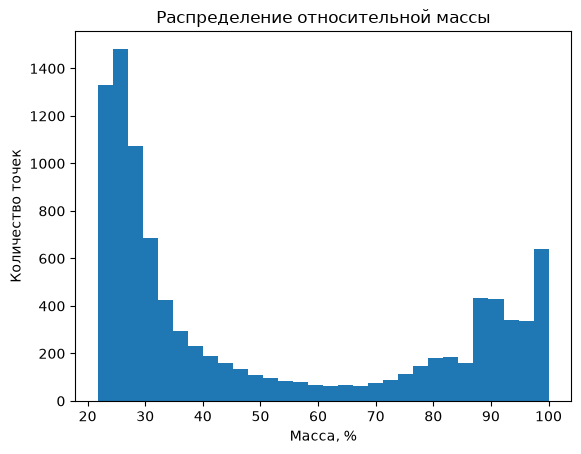

In [10]:
import matplotlib.pyplot as plt

plt.hist(df["mass_percent"], bins=30)

plt.xlabel("Масса, %")
plt.ylabel("Количество точек")
plt.title("Распределение относительной массы")

plt.show()

**Вывод:** Распределение относительной массы неравномерное. Наибольшее количество точек приходится на области примерно 23–35% и 87–100%.

Такое распределение может быть связано с характером изменения массы образцов при нагревании. Однако по одной гистограмме нельзя определить температурные интервалы потери массы, поэтому необходимо рассмотреть зависимости массы от температуры.

### Кривые термогравиметрического анализа

Построим зависимости относительной массы от температуры для всех измерений, чтобы визуально проверить непрерывность данных и выявить возможные аномалии.

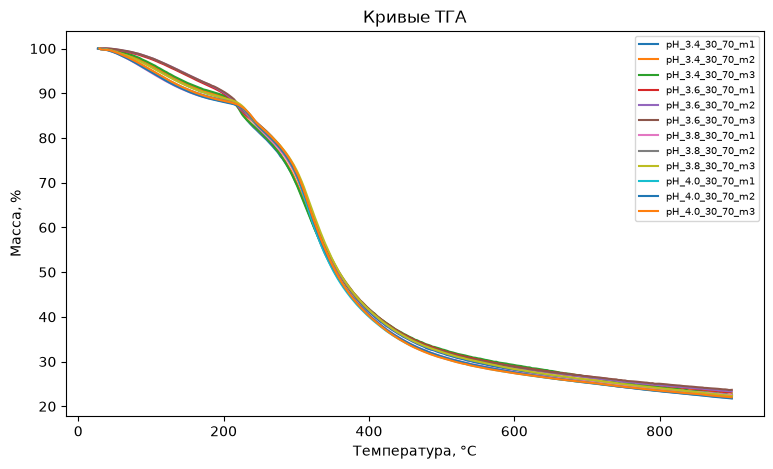

In [11]:
plt.figure(figsize=(9, 5))

for sample_id, group in df.groupby("sample_id"):
    plt.plot(group["temperature_C"], group["mass_percent"], label=sample_id)

plt.xlabel("Температура, °C")
plt.ylabel("Масса, %")
plt.title("Кривые ТГА")
plt.legend(fontsize=7)
plt.show()

**Вывод:** Все кривые ТГА имеют похожую форму и не содержат заметных резких скачков или разрывов. Основная потеря массы происходит примерно в диапазоне 250–400 °C. При высоких температурах значения остаточной массы у разных образцов близки.

Измерение с температурным шагом 5 °C также соответствует общей форме кривых, однако меньшая плотность точек может ограничивать точность анализа отдельных участков. В целом визуальный анализ не выявил существенных аномалий.

## 9. Анализ выбросов

Проверим распределение исходной массы навесок с помощью диаграммы размаха. Для этого будем использовать по одному значению массы для каждого измерения, а не все температурные точки.

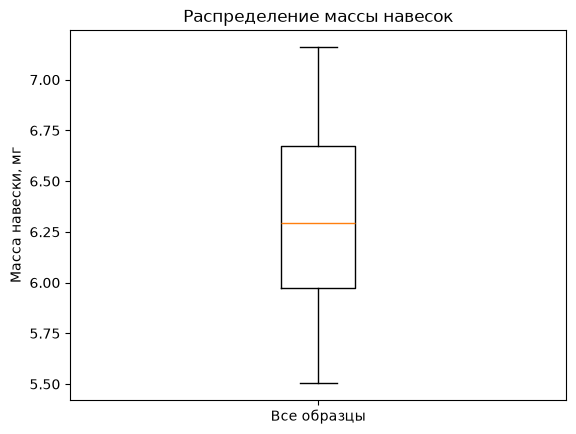

In [12]:
sample_masses = df.groupby("sample_id")["sample_mass_mg"].first()

plt.boxplot(sample_masses, tick_labels=["Все образцы"])

plt.ylabel("Масса навески, мг")
plt.title("Распределение массы навесок")

plt.show()

**Вывод:** Масса навесок находится в диапазоне от 5,505 до 7,161 мг, медиана составляет примерно 6,3 мг. Статистических выбросов по правилу 1,5 IQR не обнаружено.

Различия в исходной массе образцов не обязательно указывают на проблемы с данными, поскольку для ТГА используются навески разной массы.

## 10. Проверка согласованности данных

Проверим, соответствует ли изменение температуры со временем заданной скорости нагрева 10 К/мин.

In [13]:
heating_check = df.sort_values(["sample_id", "time_min"]).copy()

heating_check["temp_diff"] = heating_check.groupby("sample_id")["temperature_C"].diff()
heating_check["time_diff"] = heating_check.groupby("sample_id")["time_min"].diff()

heating_check["calculated_rate"] = (
    heating_check["temp_diff"] / heating_check["time_diff"]
)

heating_check.groupby("sample_id")["calculated_rate"].agg(["min", "median", "max"])

,min,median,max
sample_id,,,
pH_3.4_30_70_m1,3.683920,10.0005,12.433172
pH_3.4_30_70_m2,3.102122,9.9990,12.843565
pH_3.4_30_70_m3,2.763423,10.0000,13.149244
pH_3.6_30_70_m1,5.167852,9.9982,12.261213
pH_3.6_30_70_m2,2.503380,9.9990,13.192612
pH_3.6_30_70_m3,2.297583,10.0000,13.347571
pH_3.8_30_70_m1,3.544842,9.9980,12.615113
pH_3.8_30_70_m2,3.190098,9.9990,12.759985
pH_3.8_30_70_m3,3.744617,9.9980,12.285012


**Вывод:** Медианная скорость нагрева во всех 12 измерениях близка к заданному значению 10 К/мин. Это указывает на общую согласованность данных температуры и времени.

При этом минимальные и максимальные рассчитанные значения отклоняются от 10 К/мин. Возможными причинами являются особенности регистрации данных, округление временных значений или изменение скорости нагрева на отдельных участках. Причина отклонений требует дополнительной проверки.

In [14]:
print("Нулевые интервалы времени:",
      (heating_check["time_diff"] == 0).sum())

print("Отрицательные интервалы времени:",
      (heating_check["time_diff"] < 0).sum())

print("Нулевые интервалы температуры:",
      (heating_check["temp_diff"] == 0).sum())

Нулевые интервалы времени: 0
Отрицательные интервалы времени: 0
Нулевые интервалы температуры: 0


**Вывод:** В данных не обнаружено нулевых или отрицательных временных интервалов, а также нулевых изменений температуры между соседними точками. Это подтверждает последовательность регистрации данных и отсутствие повторяющихся временных отметок внутри измерений.

## 11. Заключение

В ходе EDA был исследован датасет термогравиметрического анализа гидрогелей, содержащий 9 768 строк и 18 столбцов.

Проверка показала, что в данных отсутствуют пропущенные значения и полностью дублирующиеся строки. Типы данных соответствуют содержимому столбцов.

Датасет включает 12 измерений при четырёх значениях pH. При этом обнаружена особенность одного измерения (`pH_3.6_30_70_m1`): его температурный шаг составляет 5 °C, тогда как у остальных измерений — 1 °C. Это необходимо учитывать при сравнении данных.

Также выявлены небольшие превышения относительной массы выше 100% и положительные значения ДТГ. Они могут быть связаны с особенностями экспериментальных данных и требуют внимания, но на данном этапе не были признаны ошибочными.

Положительные значения ДТГ распределены между образцами неравномерно. Чаще всего они встречаются при pH 3,4 и 3,6, тогда как при pH 3,8 они отсутствуют. Это может быть связано с особенностями экспериментальных кривых или регистрации сигнала и требует дополнительного изучения.

Визуальный анализ кривых ТГА не выявил значительных разрывов или резких скачков. Медианная скорость нагрева соответствует заданному значению 10 К/мин, а последовательность временных и температурных точек не нарушена.

**В целом датасет пригоден для дальнейшего анализа, однако необходимо учитывать различия в температурном шаге и отдельные потенциально аномальные значения.**

## 12. Расширенная визуализация

Для более подробного сравнения измерений построим кривые ДТГ при разных значениях pH с помощью библиотеки Seaborn.

Каждое значение pH будет представлено на отдельном графике, а повторные измерения — разными цветами.

Text(0.5, 1.03, 'Сравнение кривых ДТГ при разных pH')

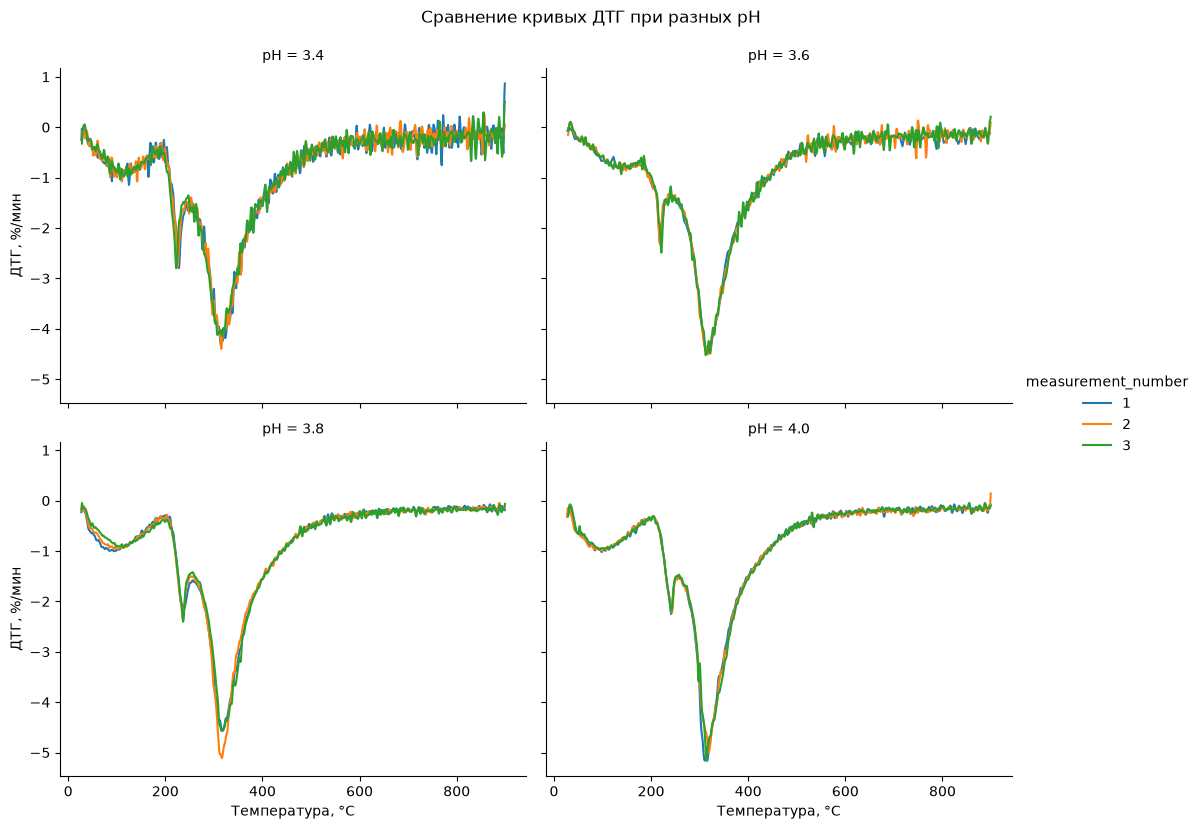

In [15]:
import seaborn as sns

g = sns.relplot(
    data=df,
    x="temperature_C",
    y="dtg_pct_per_min",
    col="ph",
    col_wrap=2,
    hue="measurement_number",
    palette="tab10",
    kind="line",
    estimator=None,
    height=4,
    aspect=1.3
)

g.set_axis_labels("Температура, °C", "ДТГ, %/мин")
g.set_titles("pH = {col_name}")
g.figure.suptitle("Сравнение кривых ДТГ при разных pH", y=1.03)

**Вывод:** Кривые ДТГ при всех исследованных значениях pH имеют похожую форму. Наиболее интенсивная потеря массы наблюдается примерно в диапазоне 300–330 °C. Повторные измерения в целом хорошо согласуются между собой, хотя глубина отдельных минимумов немного различается.

При высоких температурах наблюдаются колебания сигнала, особенно заметные для образцов при pH 3,4. Построение отдельных графиков для каждого значения pH позволило подробнее сравнить особенности термического разложения и воспроизводимость измерений.